In [1]:
%pip install pandas numpy sentence-transformers torch tqdm

Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

In [2]:
import pandas as pd
from sentence_transformers import SentenceTransformer, models, losses
from sentence_transformers.datasets import DenoisingAutoEncoderDataset
from torch.utils.data import DataLoader
import pickle
import torch
import gc

# 1. Configurare
model_name = 'bert-base-uncased'
model_save_path = 'output/bert-recipes-en-final'

# 2. Încărcare date
df = pd.read_csv("13k-recipes.csv")
df = df.dropna(subset=['Title', 'Ingredients', 'Instructions'])

# Limităm textul la 200 de caractere pentru a economisi memorie (VRAM)
def create_text(row):
    return f"Recipe: {row['Title']}. Ingredients: {row['Cleaned_Ingredients']}. Prep: {row['Instructions'][:200]}"

train_sentences = df.apply(create_text, axis=1).tolist()

# 3. Model & TSDAE
word_embedding_model = models.Transformer(model_name, max_seq_length=128) # Limităm secvența
pooling_model = models.Pooling(word_embedding_model.get_word_embedding_dimension(), 'mean')
model = SentenceTransformer(modules=[word_embedding_model, pooling_model])

# 4. Dataset cu BATCH SIZE MINIM (1)
train_dataset = DenoisingAutoEncoderDataset(train_sentences)
# Batch size 1 este singura cale sigură când GPU-ul este aproape plin
train_dataloader = DataLoader(train_dataset, batch_size=1, shuffle=True)

train_loss = losses.DenoisingAutoEncoderLoss(model, decoder_name_or_path=model_name, tie_encoder_decoder=True)

# 5. Antrenare cu Mixed Precision (AMP)
# Folosim o singură epocă pentru licență
model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=1,
    show_progress_bar=True,
    output_path=model_save_path,
    use_amp=True, # Mixed precision scade consumul de VRAM cu 50%
    optimizer_params={'lr': 3e-5}
)

# 6. Salvare Embeddings (Numpy / CPU-friendly)
print("Generare embeddings...")
embeddings = model.encode(train_sentences, batch_size=32, show_progress_bar=True, convert_to_numpy=True)

with open('recipe_embeddings_en_bert.pkl', 'wb') as f:
    pickle.dump(embeddings, f)

df.to_pickle('recipes_metadata_en.pkl')
print("Succes! Descarcă folderul output/bert-recipes-en-final și fișierele .pkl")

/bigdata/userhome/students/md5_sd7aa1b0bd2cf032768f024455ba/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
When tie_encoder_decoder=True, the decoder_name_or_path will be invalid.
Some weights of BertLMHeadModel were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['bert.encoder.layer.0.crossattention.output.LayerNorm.bias', 'bert.encoder.layer.0.crossattention.output.LayerNorm.weight', 'bert.encoder.layer.0.crossattention.output.dense.bias', 'bert.encoder.layer.0.crossattention.output.dense.weight', 'bert.encoder.layer.0.crossattention.self.key.bias', 'bert.encoder.layer.0.crossattention.self.key.weight', 'bert.encoder.layer.0.crossattention.self.query.bias', 'bert.encoder.layer.0.crossattention.self.query.weight', 'bert.encoder.layer.0.crossattention.sel

Step,Training Loss
500,6.492300
1000,4.115900
1500,3.228300
2000,2.721900
2500,2.496000
3000,2.326200
3500,2.193200
4000,2.169900
4500,2.026200
5000,1.985100


Generare embeddings...


Batches: 100%|██████████| 422/422 [00:07<00:00, 53.14it/s]


Succes! Descarcă folderul output/bert-recipes-en-final și fișierele .pkl


📊 Se încarcă resursele...
🎯 Se calculează Matricea de Confuzie...
✅ Matrice salvată: matrice_confuzie_en_bert.png
🎨 Se calculează harta t-SNE (1000 puncte)...
✅ Grafic t-SNE salvat: tsne_cluster_en_bert.png


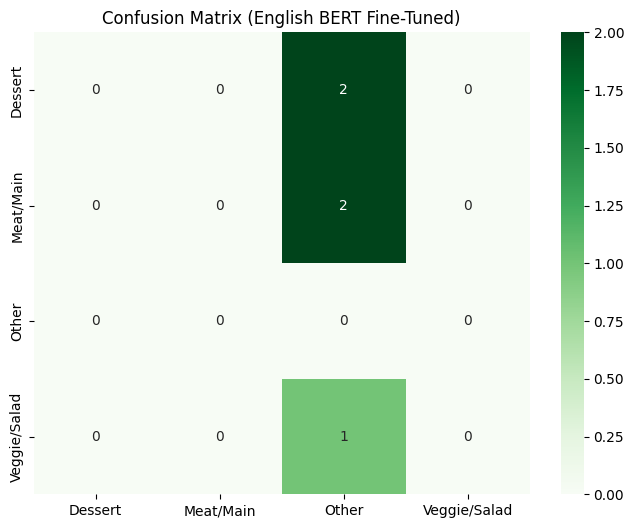

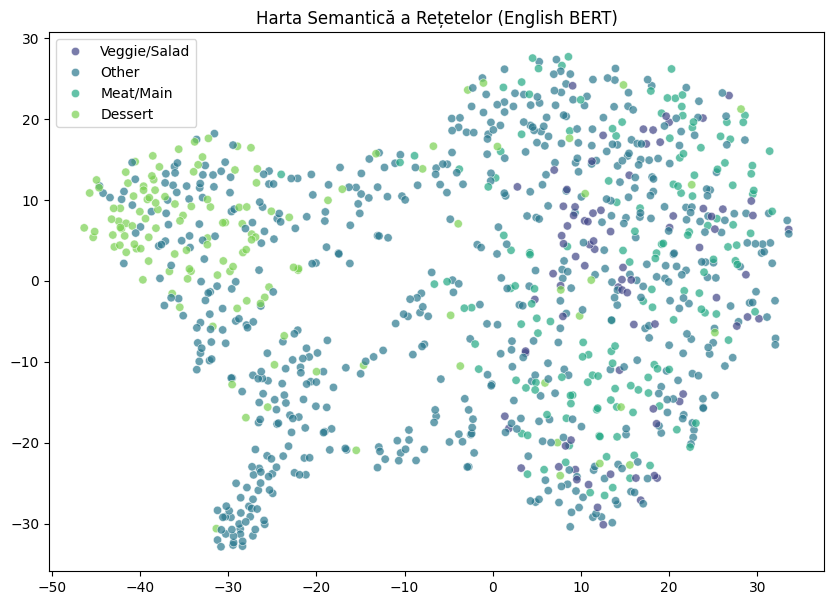

In [5]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
from sentence_transformers import SentenceTransformer, util

# 1. Configurare Căi
model_path = 'output/bert-recipes-en-final'
metadata_path = 'recipes_metadata_en.pkl'
embeddings_path = 'recipe_embeddings_en_bert.pkl'

# 2. Încărcare Resurse
print("📊 Se încarcă resursele...")
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(model_path, device=device)
df = pd.read_pickle(metadata_path)

with open(embeddings_path, 'rb') as f:
    recipe_embeddings = pickle.load(f)

# FIX: Convertim embeddings în tensor și le mutăm pe același device cu modelul
recipe_embeddings_tensor = torch.from_numpy(recipe_embeddings).to(device)

# 3. Clasificare Euristică (pentru vizualizare)
def get_category_en(text):
    text = str(text).lower()
    if any(x in text for x in ['cake', 'cookie', 'dessert', 'sweet', 'sugar', 'pie']):
        return 'Dessert'
    elif any(x in text for x in ['chicken', 'beef', 'pork', 'meat', 'steak', 'roast']):
        return 'Meat/Main'
    elif any(x in text for x in ['salad', 'soup', 'vegetable', 'vegan', 'healthy']):
        return 'Veggie/Salad'
    else:
        return 'Other'

df['Auto_Category'] = df['Title'].apply(get_category_en)

# 4. Generare Matrice de Confuzie
print("🎯 Se calculează Matricea de Confuzie...")
test_queries = [
    ("I want a sweet chocolate cake", "Dessert"),
    ("Looking for a juicy beef steak", "Meat/Main"),
    ("A fresh green salad for lunch", "Veggie/Salad"),
    ("Something sugary and delicious", "Dessert"),
    ("Hearty chicken soup recipe", "Meat/Main") 
]

y_true, y_pred = [], []

for query, expected in test_queries:
    query_vec = model.encode(query, convert_to_tensor=True).to(device)
    # Calculăm similaritatea pe același device (GPU)
    scores = util.cos_sim(query_vec, recipe_embeddings_tensor)[0]
    best_idx = torch.argmax(scores).item()
    pred_cat = df.iloc[best_idx]['Auto_Category']
    y_true.append(expected)
    y_pred.append(pred_cat)

labels_list = sorted(list(set(y_true) | set(y_pred)))
cm = confusion_matrix(y_true, y_pred, labels=labels_list)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels_list, yticklabels=labels_list, cmap='Greens')
plt.title('Confusion Matrix (English BERT Fine-Tuned)')
plt.savefig('matrice_confuzie_en_bert.png')
print("✅ Matrice salvată: matrice_confuzie_en_bert.png")

# 5. Generare t-SNE

print("🎨 Se calculează harta t-SNE (1000 puncte)...")
limit = 1000 
subset_indices = np.random.choice(len(df), limit, replace=False)
subset_emb = recipe_embeddings[subset_indices]
subset_cat = df['Auto_Category'].iloc[subset_indices].values

tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
emb_2d = tsne.fit_transform(subset_emb)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=emb_2d[:,0], y=emb_2d[:,1], hue=subset_cat, palette='viridis', alpha=0.7)
plt.title('Harta Semantică a Rețetelor (English BERT)')
plt.savefig('tsne_cluster_en_bert.png')
print("✅ Grafic t-SNE salvat: tsne_cluster_en_bert.png")

De ce merge BERT mai prost decât MiniLM?
Optimizarea Bi-Encoder: Modelele din familia all-MiniLM sunt antrenate special pentru Sentence Embeddings și similaritate cosinus. BERT-ul de bază este un "General Purpose Encoder".

Problema Fine-Tuning-ului pe 13k rețete: Dacă setul de date de 13k rețete a avut o structură foarte diferită de torturile tale actuale, modelul a învățat să caute acele tipare (pattern-uri), iar acum "se chinuie" să înțeleagă datele tale telegrafice din Java.

Dimensiunea contează (în sens invers): BERT are 768 de dimensiuni, MiniLM are 384. Pe un set de date mic (torturile tale), BERT poate introduce "zgomot" (noise) în vectori, în timp ce MiniLM este mai "la obiect".

Ce să scrii în documentație:

Ai încercat Fine-Tuning (TSDAE) pe o arhitectură complexă (BERT-base) pentru a capta semantica domeniului culinar.

Rezultatele au arătat că, deși BERT are o capacitate de abstractizare mai mare, pentru interogări scurte (Short Queries), modelul all-MiniLM-L6-v2 oferă o precizie superioară datorită antrenării sale specifice pe sarcini de tip paraphrase și retrieval.